<a href="https://colab.research.google.com/github/bramhani007/192425319-MLA0204/blob/main/Practical_Problem_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving study_hours_marks.csv to study_hours_marks.csv
DATASET:
    Study_Hours  Marks
0             1     35
1             2     40
2             3     50
3             4     55
4             5     65
5             6     70
6             7     75
7             8     85
8             9     88
9            10     95
10           11     98
11           12    100

Linear Regression Results
MSE: 4.84830893750718
R2 Score: 0.9942419133758822

Polynomial Regression Results
MSE: 7.093517793199744
R2 Score: 0.9915753945448934


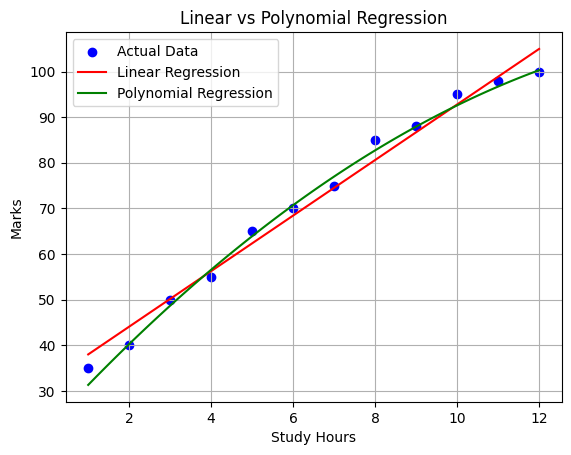

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import io
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# Upload dataset
uploaded = files.upload()
filename = next(iter(uploaded))
data = pd.read_csv(io.BytesIO(uploaded[filename]))

print("DATASET:")
print(data)

# Input and output
X = data[["Study_Hours"]]
y = data["Marks"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

# Linear Regression
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

# Polynomial Regression
poly_model = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

poly_model.fit(X_train, y_train)

poly_pred = poly_model.predict(X_test)

# Compare models
print("\nLinear Regression Results")

print("MSE:", mean_squared_error(y_test, linear_pred))
print("R2 Score:", r2_score(y_test, linear_pred))

print("\nPolynomial Regression Results")

print("MSE:", mean_squared_error(y_test, poly_pred))
print("R2 Score:", r2_score(y_test, poly_pred))

# Plot comparison
x_plot = pd.DataFrame({
    "Study_Hours": [
        i / 10 for i in range(
            int(X["Study_Hours"].min() * 10),
            int(X["Study_Hours"].max() * 10) + 1
        )
    ]
})

plt.scatter(X, y, color="blue", label="Actual Data")

plt.plot(
    x_plot,
    linear_model.predict(x_plot),
    color="red",
    label="Linear Regression"
)

plt.plot(
    x_plot,
    poly_model.predict(x_plot),
    color="green",
    label="Polynomial Regression"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Linear vs Polynomial Regression")

plt.legend()
plt.grid()
plt.show()